In [1]:
from matplotlib import pyplot as plt
import numpy as np
from scipy.special import jv, kv
from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate

In [2]:
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0

In [34]:
import sys
from pathlib import Path
import joblib
import time

src_path = Path("/Users/tliu/oh_suppression/codes/src")

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from oh_suppression.coupling import *

In [4]:
from oh_suppression.point_source_coupling import *
from oh_suppression.flat_background_coupling import *
from oh_suppression.extended_source_coupling import *

In [5]:
from matplotlib import pyplot as plt
import numpy as np
from scipy import special #import jv, kv
# from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0
from scipy.optimize import brentq
from scipy.optimize import fminbound
from dataclasses import dataclass
import pandas as pd
from joblib import Parallel, delayed
import os

In [6]:
import astropy.units as u
from astropy.modeling.models import Moffat1D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Moffat1D.html
from astropy.modeling.functional_models import Moffat2D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Moffat2D.html


In [15]:
from scipy.interpolate import RegularGridInterpolator
from scipy.interpolate import PchipInterpolator
from tqdm.auto import tqdm

/Users/tliu/.conda/envs/oh_suppression_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
def Moffat_1d_profile(amplitude, x_0, gamma, alpha): 
    """
    Returns a 1D Moffat profile function.
    
    Parameters:
    amplitude : float
        The peak value of the profile.
    x_0 : float
        The position of the peak.
    gamma : float
        The scale parameter, related to the FWHM.
    alpha : float
        The shape parameter, controlling the wings of the profile.
    
    Returns:
    function
        A function that computes the Moffat profile at given x values.
    """
    def profile(x):
        return amplitude * (1 + ((x - x_0) / gamma) ** 2) ** (-alpha)
    
    return profile

### Point source coupling jitter effect

In [12]:
def sigma_jitter_milliarcsec_to_metres(sigma_jitter_rms, focal_length, demagnification): 
    """
    Convert the RMS jitter from milliarcseconds to metres at the fibre plane.

    Parameters: 
    sigma_jitter_rms : float
        RMS jitter in milliarcseconds.
    focal_length : float
        Focal length of the telescope in metres.
    demagnification : float 
        Demagnification factor from the telescope focal plane to the fibre plane, done by the reimaging optics. 

    Returns:
    float
        RMS jitter in metres at the fibre plane.
    """
    # Convert jitter from milliarcseconds to radians
    sigma_theta_radians = sigma_jitter_rms * 1e-3 / 206265 

    # Convert jitter from radians to physical units (metres) at the fibre plane using the focal length and demagnification

    sigma_jitter_metres = demagnification * focal_length * sigma_theta_radians

    return sigma_jitter_metres

In [9]:
def radial_to_eta_map(
        eta_psf_interp,
        decentre_array: np.ndarray,
        x: np.ndarray,
        y: np.ndarray
) -> np.ndarray:
    """
    Convert a radial point-source coupling efficiency function
    into a 2D coupling efficiency map.
    """

    # Calculate the radial distance from the fibre centre.
    r_grid = np.sqrt(x**2 + y**2)

    # Create an empty array for the 2D coupling map.
    eta_map_2d = np.zeros_like(r_grid)

    # Select positions covered by the calculated radial response.
    inside_range = r_grid <= decentre_array[-1]

    # Interpolate the radial coupling efficiency onto the 2D grid.
    eta_map_2d[inside_range] = eta_psf_interp(
        r_grid[inside_range]
    )

    return eta_map_2d

In [10]:
def generate_jitter_positions(
    sigma_jitter_rms_mas: float,
    focal_length: float,
    demagnification: float,
    n_samples: int,
    rng: np.random.Generator
) -> tuple[np.ndarray, np.ndarray]:
    """
    Generate random x and y tip-tilt jitter displacements at the fibre plane. 
    The displacements are drawn from a normal distribution with mean 0 and standard deviation corresponding to 
    the RMS jitter specified in milliarcseconds.
    This is a helper function to generate random jitter positions for Monte Carlo simulations of coupling efficiency.

    Parameters
    ----------
    sigma_jitter_rms_mas:
        RMS jitter in milliarcseconds.

    focal_length:
        Telescope focal length in metres.

    demagnification:
        Demagnification factor between the telescope focal plane
        and the fibre plane.

    n_samples:
        Number of random jitter positions.

    rng:
        NumPy random number generator.

    Returns
    -------
    delta_x, delta_y:
        Random x and y jitter displacements at the fibre plane, in metres.
    """

    # Convert RMS jitter from milliarcseconds to metres at the fibre plane.
    sigma_jitter_metres = sigma_jitter_milliarcsec_to_metres(
        sigma_jitter_rms_mas,
        focal_length,
        demagnification
    )

    # Generate random x jitter positions.
    delta_x = rng.normal(
        loc=0,
        scale=sigma_jitter_metres,
        size=n_samples
    )

    # Generate random y jitter positions.
    delta_y = rng.normal(
        loc=0,
        scale=sigma_jitter_metres,
        size=n_samples
    )

    return delta_x, delta_y

In [27]:
def Monte_Carlo_point_source_coupling(
    x, y, 
    x_1d, y_1d,
    delta_x, delta_y, 
    eta_map_fixed: np.ndarray,
    acceptance_radius=None,
    fibre_x=0.0,
    fibre_y=0.0,
):
    """
    Perform a Monte Carlo simulation to calculate the coupling efficiency
    of a point source in the presence of tip-tilt jitter.

    For each random jitter position, the point source position is evaluated
    on the fixed 2D coupling efficiency map.

    Parameters
    ----------
    x_1d : 1D array of x-coordinates at the fibre plane, in metres.

    y_1d : 1D array of y-coordinates at the fibre plane, in metres.

    delta_x : Random x-direction jitter displacements at the fibre plane, in metres.

    delta_y : Random y-direction jitter displacements at the fibre plane, in metres.

    eta_map_fixed : np.ndarray
        Fixed 2D point-source coupling efficiency map.

    acceptance_radius : float or None
        Radius of the circular acceptance region, in metres.

        If None, no additional circular acceptance boundary is applied.

        If a radius is given, coupling is set to zero when the point
        source is outside this radius.

    fibre_x : float
        Fixed x-position of the fibre centre, in metres.

    fibre_y : float
        Fixed y-position of the fibre centre, in metres.

    Returns
    -------
    eta_samples : np.ndarray
        Coupling efficiency for each Monte Carlo jitter position.
    """

    # Number of Monte Carlo samples determined by the number of jitter positions provided.
    n_samples = len(delta_x)

    # Create an empty array in which to store the coupling efficiency for each jitter position.
    eta_samples = np.zeros(n_samples)


    # Apply a circular acceptance boundary if one is specified.
    if acceptance_radius is not None:

        # Mask the 2D coupling efficiency map to only include points within the acceptance radius.
        acceptance_mask = (
            np.sqrt(
                (x - fibre_x)**2
                + (y - fibre_y)**2
            )
            <= acceptance_radius
        )
        
        eta_map_fixed = eta_map_fixed.copy() 
        eta_map_fixed[~acceptance_mask] = 0.0

        # # Calculate the radial position of each point source.
        # radial_displacement = np.sqrt(
        #     delta_x**2 + delta_y**2
        # )

    for i in range(n_samples):
        # Calculate the shifted position (in physical units) of th point source due to jitter.
        dx_metre = delta_x[i]
        dy_metre = delta_y[i]

        # Find the closest x-grid position to the jittered point source, x_1d - dx_metre is 1d array minus a scalar, 
        # so the result is a 1d array of the same length as x_1d. np.abs gives the absolute value of each element in that array, 
        # and np.argmin returns the index of the minimum value in that array. This index corresponds to the closest x-grid position 
        # to the jittered point source.
        x_index = np.argmin(np.abs(x_1d - dx_metre)) 

        # Find the closest y-grid position to the jittered point source
        y_index = np.argmin(np.abs(y_1d - dy_metre))

        # Evaluate the coupling efficiency at the shifted position.
        eta_samples[i] = eta_map_fixed[y_index, x_index]

    return eta_samples

In [18]:
# wavelength of beam in vacuum
lam0 = 1.5e-6 
# numerical aperture of fibre
NA = 0.1 

# # Calculate the normalised frequency (V-number) of the fibre
# V = 2 * pi * (a / lam0) * NA
# print(f"V-number of the fibre: {V:.2f}")

In [24]:
f_coude = 399
F_fibre = 1 / (2 * np.tan(np.arcsin(NA)))
Magnification = F_fibre / 49.9
F_focus = 49.9
D_M1 = 8.0
D_M1 = 8.0 # Diameter of the primary mirror in meters
D_obstruction = 1.0 # Diameter of the central obstruction in meters
alpha_vlt = D_obstruction / D_M1 # Ratio of the central obstruction to the primary mirror diameter
rad_to_arcsec = (180 / np.pi) * 3600
plate_scale_coude = rad_to_arcsec / (F_focus * D_M1)  # arcsec / metre at telescope focal plane
plate_scale_demag = plate_scale_coude / Magnification # arcsec / metre at the demagnified fibre input plane

In [17]:
r_max = 125e-6  # maximum radial distance from the fibre centre, in metres
x_1d = np.linspace(-r_max, r_max, 1000) # x-coordinates at the fibre plane, in metres
y_1d = np.linspace(-r_max, r_max, 1000) # y-coordinates at the fibre plane, in metres
x, y = np.meshgrid(x_1d, y_1d)

In [20]:
# Only test for a single normalised frequency at r=5.7microns for my first test of decentred position
prepared_smf_mode_5p7micron = prepare_modes_2d(
                                x, y,
                                a=5.7e-6, 
                                NA=NA, 
                                lam0=lam0, 
                                az_sym=True, 
                                mode_case="few_mode"
                            )

In [22]:
decentre_array_cladding = np.linspace(0, r_max, 500) # array of decentre positions from 0 to r_max, in meters

eta_psf_clad_5p7_decent_array, mode_result_single_5p7_clad = eta_psf_vs_radial_decentre_position(
    prepared_smf_mode_5p7micron,
    x, y, x_1d, y_1d,
    lam0=lam0,
    F_eff=F_fibre,
    alpha=alpha_vlt,
    decentre_array=decentre_array_cladding,
    E_S=1.0,
    direction_angle=0.0
)

In [23]:
a_test = 5.7e-6

eta_psf_interp = PchipInterpolator(
    decentre_array_cladding,
    eta_psf_clad_5p7_decent_array,
    extrapolate=False
)

eta_map_fixed_5p7 = radial_to_eta_map(
    eta_psf_interp=eta_psf_interp,
    decentre_array=decentre_array_cladding,
    x=x,
    y=y
)

In [133]:
delta_x, delta_y = generate_jitter_positions(
    sigma_jitter_rms_mas=20.0,  # RMS jitter in milliarcseconds
    focal_length=f_coude,  # Focal length of the telescope in metres
    demagnification=Magnification,  # Demagnification factor
    n_samples=1000,  # Number of random jitter positions
    rng=np.random.default_rng(seed=42)  # Random number generator with a fixed seed
)

In [134]:
eta_samples_point_5p7 = Monte_Carlo_point_source_coupling(
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    delta_x=delta_x,
    delta_y=delta_y,
    eta_map_fixed=eta_map_fixed_5p7,
    acceptance_radius=None,
    fibre_x=0.0,
    fibre_y=0.0
)

print("Number of Monte Carlo samples:", len(eta_samples_point_5p7))
print("Mean coupling efficiency:", np.mean(eta_samples_point_5p7))
print("Standard deviation:", np.std(eta_samples_point_5p7, ddof=1))
print(
    "Standard error:",
    np.std(eta_samples_point_5p7, ddof=1)
    / np.sqrt(len(eta_samples_point_5p7))
)

Number of Monte Carlo samples: 1000
Mean coupling efficiency: 0.35924809295188415
Standard deviation: 0.2222541007482455
Standard error: 0.0070282917767698905


In [135]:
eta_samples_point_5p7 = Monte_Carlo_point_source_coupling(
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    delta_x=delta_x,
    delta_y=delta_y,
    eta_map_fixed=eta_map_fixed_5p7,
    acceptance_radius=5.7e-6,  # Acceptance radius in metres
    fibre_x=0.0,
    fibre_y=0.0
)

print("Number of Monte Carlo samples:", len(eta_samples_point_5p7))
print("Mean coupling efficiency:", np.mean(eta_samples_point_5p7))
print("Standard deviation:", np.std(eta_samples_point_5p7, ddof=1))
print(
    "Standard error:",
    np.std(eta_samples_point_5p7, ddof=1)
    / np.sqrt(len(eta_samples_point_5p7))
)

Number of Monte Carlo samples: 1000
Mean coupling efficiency: 0.3246962921607583
Standard deviation: 0.26026768217628277
Standard error: 0.008230386770098628


## Define function that sweeps the jitter affected coupling efficiency as a function of radius

In [136]:
def jittered_point_src_eta_vs_core_radius(
        core_radius_array, 
        eta_fixed_list, 
        decentre_array, 
        x, y, 
        x_1d, y_1d,
        delta_x, delta_y,
        # plate_scale_demag,
        fibre_x=0.0, fibre_y=0.0,
        acceptance_radius="core_radius",
        n_jobs=1
):
    """
    Calculate the mean jittered point source coupling efficiency for each
    pre-calculated fixed fibre coupling map. 
    """

    # Check that there is one eta(r) array for every core radius. 

    if len(core_radius_array) != len(eta_fixed_list):
        raise ValueError(
            "core_radius_array and eta_fixed_list must have "
            "the same length."
        )

    # Number of core radii
    n_radius = len(core_radius_array)

    # Number of Monte Carlo jitter samples
    n_samples = len(delta_x)

    # Create empty arrays for the average coupling, the standard deviation of eta vs displacement 
    # due to jitter and the error calculated from that std

    def run_one_radius(core_radius, eta_fixed): 
        # Loop over the fixed coupling map for each fibre core radius.

        # Convert radial eta(r^vector) into a 2D fixed coupling map.
        eta_psf_interp = PchipInterpolator(
            decentre_array, 
            eta_fixed, 
            extrapolate=False
        )

        eta_map_fixed = radial_to_eta_map(
            eta_psf_interp=eta_psf_interp, 
            decentre_array=decentre_array, 
            x=x, 
            y=y
        )

        if acceptance_radius == "core_radius":
            acceptance_radius_this = core_radius
        else:
            acceptance_radius_this = acceptance_radius

        # Calculate the point source coupling efficiency at every random jitter position
        # using Monte Carlo Averaging

        eta_samples = Monte_Carlo_point_source_coupling(
            x=x, y=y,
            x_1d=x_1d,
            y_1d=y_1d,
            delta_x=delta_x,
            delta_y=delta_y,
            eta_map_fixed=eta_map_fixed,
            acceptance_radius=acceptance_radius_this,
            fibre_x=fibre_x, fibre_y=fibre_y
        )

        # Mean coupling efficiency
        eta_mean = np.mean(eta_samples)

        # The standard deviation or the distribution or the extent of physical variation
        # in the coupling due to jitter
        eta_std = np.std(
            eta_samples,
            ddof=1
        )

        # The standard error of the Monte Carlo mean = 1/N * ∑ eta_i
        eta_error = (
            eta_std / np.sqrt(n_samples)
        )

        return eta_mean, eta_std, eta_error

    if n_jobs == 1:
        
        results = [
            run_one_radius(core_radius, eta_fixed)
            for core_radius, eta_fixed in zip(
                core_radius_array,
                eta_fixed_list
            )
        ]

    else: 

        results = Parallel(
            n_jobs=n_jobs,
            verbose=10
        )(
            delayed(run_one_radius)(
                core_radius,
                eta_fixed
            )
            for core_radius, eta_fixed in zip(
                core_radius_array,
                eta_fixed_list
            )
        )

    eta_mean = np.array([
        result[0] for result in results
    ])

    eta_std = np.array([
        result[1] for result in results
    ])

    eta_error = np.array([
        result[2] for result in results
    ])

    return eta_mean, eta_std, eta_error

In [137]:
# Fibre front grid in metres

r_max = 125e-6 # maximum radius of the CLADDING region to be considered in the 2D grid, in meters
n_grid = 1000 

x_1d = np.linspace(-r_max, r_max, n_grid)
y_1d = np.linspace(-r_max, r_max, n_grid)

x, y = np.meshgrid(x_1d, y_1d)

In [138]:
checkpoint_dir = Path(
    "/Users/tliu/oh_suppression/result/Ext_source_wt_jitter_SNR"
)

corrected_file = (
    checkpoint_dir /
    "eta_tot_psf_radial_decentre_high_resolution_276rows.joblib"
)

In [139]:
core_radius_range_full = joblib.load(corrected_file)["core_radius_range_full"]
eta_tot_psf_radial_decentre_list = joblib.load(corrected_file)["eta_tot_psf_radial_decentre_list"]

In [140]:
np.shape(core_radius_range_full), np.shape(eta_tot_psf_radial_decentre_list)


((276,), (276, 500))

In [141]:
eta_mean_psf_core_acceptance, eta_std_psf_core_acceptance, eta_standard_error_psf_core_acceptance = jittered_point_src_eta_vs_core_radius(
    core_radius_array=core_radius_range_full, 
    eta_fixed_list=eta_tot_psf_radial_decentre_list, 
    decentre_array=decentre_array_cladding, 
    x=x, y=y, 
    x_1d=x_1d, y_1d=y_1d, 
    delta_x=delta_x, delta_y=delta_y, 
    # plate_scale_demag=plate_scale_demag,
    fibre_x=0.0, fibre_y=0.0,
    acceptance_radius="core_radius",  # Use the fibre core radius as the acceptance radius
    n_jobs=4
)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    1.0s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    1.1s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    1.1s
[Parallel(n_jobs=4)]: Batch computation too fast (0.19790557514441515s.) Setting batch_size=2.
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    1.2s
[Parallel(n_jobs=4)]: Batch computation too fast (0.10777688026428223s.) Setting batch_size=4.
[Parallel(n_jobs=4)]: Done  44 tasks      | elapsed:    1.5s
[Parallel(n_jobs=4)]: Done  80 tasks      | elapsed:    1.7s
[Parallel(n_jobs=4)]: Done 124 tasks      | elapsed:    2.1s
[Parallel(n_jobs=4)]: Done 168 tasks      | elapsed:    2.3s
[Parallel(n_jobs=4)]: Done 220 tasks      | elapsed:    2.9s
[Parallel(n_jobs=4)]: Done 266 tasks      | elapsed:    3.1s
[Parallel(n_jobs=4)]: Done 276 out of 276 | elapsed:    3.2s finished


In [142]:
print("Number of core radii:", len(core_radius_range_full))
print("Number of eta arrays:", len(eta_tot_psf_radial_decentre_list))
print("Number of MC samples:", len(delta_x))

print("Output lengths:")
print(len(eta_mean_psf_core_acceptance))
print(len(eta_std_psf_core_acceptance))
print(len(eta_standard_error_psf_core_acceptance))

Number of core radii: 276
Number of eta arrays: 276
Number of MC samples: 1000
Output lengths:
276
276
276


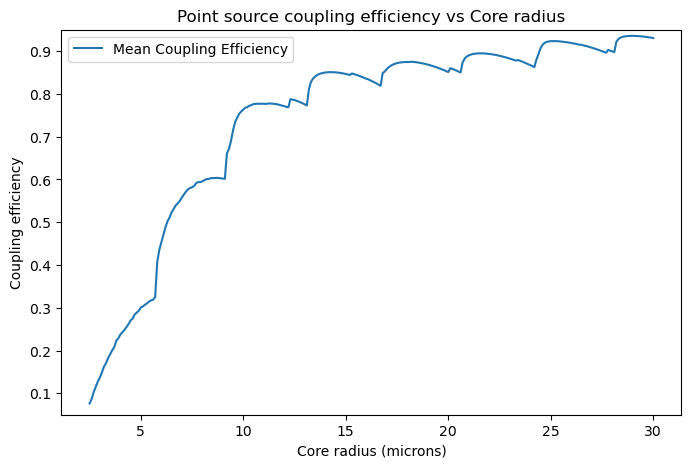

In [143]:
plt.figure(figsize=(8,5))
plt.plot(core_radius_range_full * 1e6, eta_mean_psf_core_acceptance, label="Mean Coupling Efficiency")
plt.ylim(0.05,0.95)
plt.xlabel('Core radius (microns)')
plt.ylabel('Coupling efficiency')
plt.title('Point source coupling efficiency vs Core radius')
plt.legend()

In [144]:
def radius_um_to_V(radius_um):
    radius_m = radius_um * 1e-6
    return 2 * np.pi * radius_m * NA / lam0


def V_to_radius_um_axis(V):
    radius_m = V * lam0 / (2 * np.pi * NA)
    return radius_m * 1e6

In [145]:
V_to_radius_um_axis(2.405)

5.741514572040124

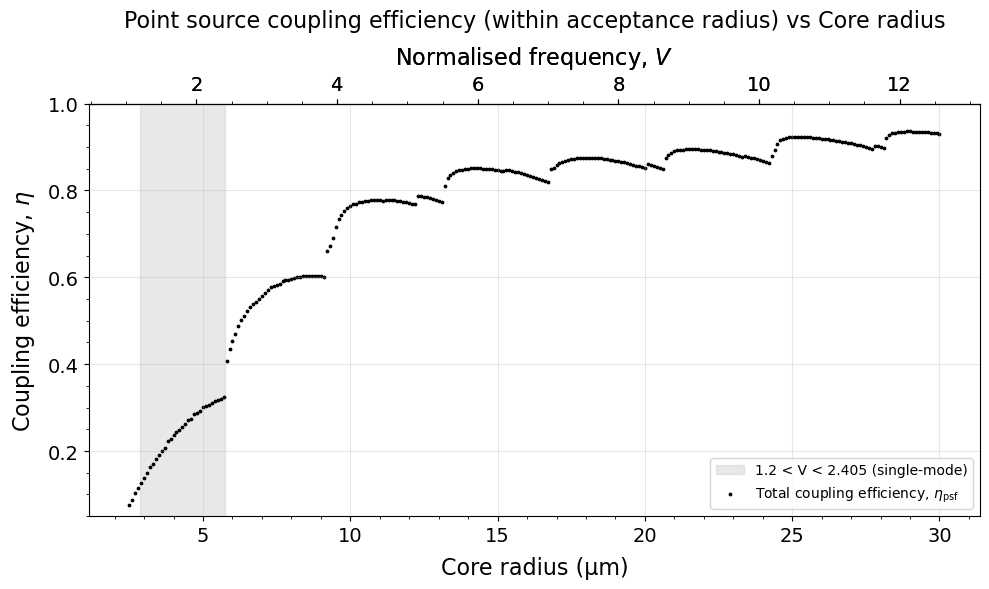

In [146]:
plt.figure(figsize=(10, 6))
ax1 = plt.gca()

# Colour in 1.2 < V < 2.405 region in light grey
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.5,
    label="1.2 < V < 2.405 (single-mode)"
)

ax1.scatter(
    core_radius_range_full * 1e6,
    eta_mean_psf_core_acceptance,
    label=r"Total coupling efficiency, $\eta_{\mathrm{psf}}$",
    color="black", s=3
)

ax1.set_xlabel("Core radius (µm)", fontsize=16, labelpad=8)
ax1.set_ylabel(r"Coupling efficiency, $\eta$", fontsize=16, labelpad=8)

ax1.tick_params(axis="x", labelsize=14)
ax1.tick_params(axis="y", labelsize=14)
ax1.minorticks_on()
ax1.grid(True, alpha=0.3)


# -------------------------------------------------
# Top axis: normalised frequency V
# -------------------------------------------------


ax2 = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax2.set_xlabel(
    r"Normalised frequency, $V$",
    fontsize=16,
    labelpad=8
)

ax2.tick_params(axis="x", labelsize=14)

ax2 = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax2.set_xlabel(
    r"Normalised frequency, $V$",
    fontsize=16,
    labelpad=8
)

ax2.tick_params(axis="x", labelsize=14)
ax2.minorticks_on()

plt.ylim(0.05, 1.0)


plt.title("Point source coupling efficiency (within acceptance radius) vs Core radius", fontsize=16, pad=12)
plt.legend()

plt.tight_layout()
plt.show()


In [158]:
# The background doesn't change, so import data 'results_bg_mmf_core_LIGHT'from the previous calculation.

results_bg_mmf_core = joblib.load('/Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_bg_mmf_core_LIGHT.joblib')
eta_bg_core = np.array([res["eta_background"] for res in results_bg_mmf_core])# [:-1] # from zeroth index to second last index

In [161]:
# SNR plot for core case

I_flat = 1 **2 # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600 # conversion factor from radians to arcseconds

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1) # in arcseconds per meter at the focal plane
plate_scale_demag = plate_scale_coude / Magnification # in arcseconds per meter at the fibre input plane

FOV_array = np.zeros_like(core_radius_range_full)
snr_array = np.zeros_like(core_radius_range_full)
signal_array = np.zeros_like(core_radius_range_full)
background_array = np.zeros_like(core_radius_range_full)

for i, a in enumerate(core_radius_range_full): 
    # # Calculate Field of View for the fibre
    # # plate scale = FOV / fibre radius, so FOV = plate scale * fibre radius (in arcseconds)
    FOV = plate_scale_demag * 2*a # in arcseconds 

    # r_FOV = np.linspace(0, FOV, 10000) * plate_scale_demag # Convert FOV from arcseconds to meters at the fibre input plane for the core region
    
    # Signal = 2*np.pi * integrate.simpson(I_image * fibre_r, x=fibre_r) # Total signal coupled into the fibre, integrating over the fibre cross-section
    Background_area = np.pi * I_flat * (FOV / 2) **2  # Total noise coupled into the fibre, integrating over the fibre cross-section

    signal = eta_mean_psf_core_acceptance[i]
    background = eta_bg_core[i] * I_flat

    snr = signal / np.sqrt(Background_area * background) # Signal-to-noise ratio, assuming noise is dominated by the background and follows Poisson statistics

    FOV_array[i] = FOV
    snr_array[i] = snr
    signal_array[i] = signal
    background_array[i] = background

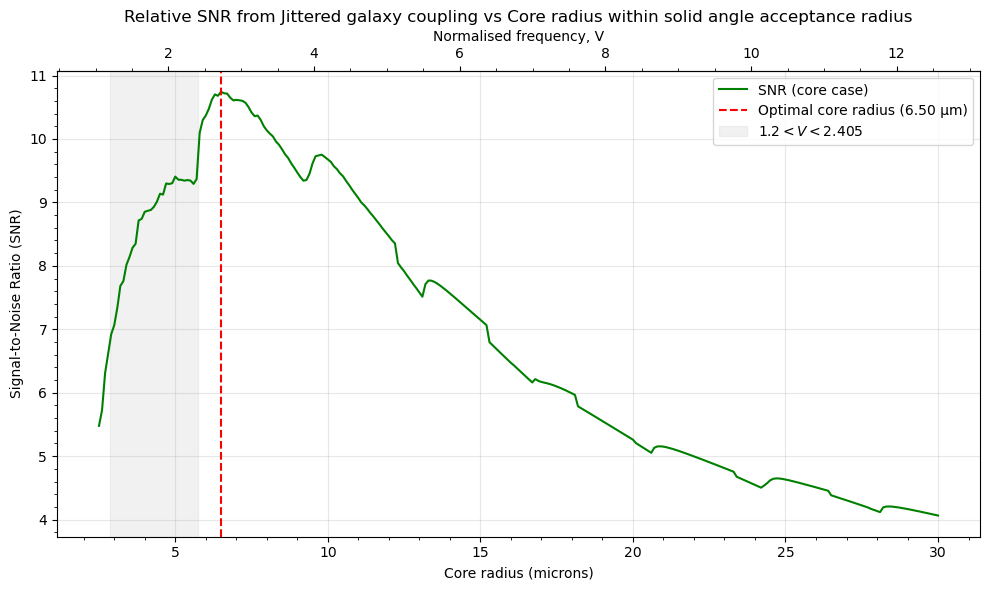

In [ ]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(core_radius_range_full*1e6, snr_array, color='g', label='SNR (core case)')

ax1.axvline(core_radius_range_full[np.argmax(snr_array)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_full[np.argmax(snr_array)] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('Relative SNR from Jittered galaxy coupling vs Core radius within solid angle acceptance radius')


ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
plt.show()

In [182]:
core_radius_range_smf = core_radius_range_full[core_radius_range_full <= 5.7415e-6]

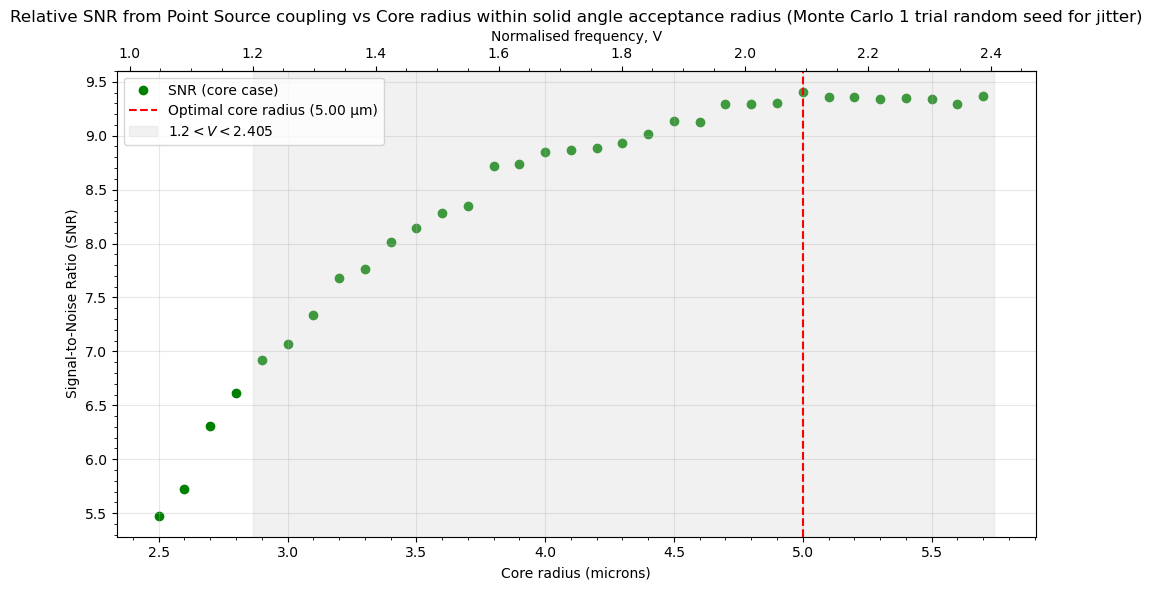

In [187]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.scatter(core_radius_range_full[:len(core_radius_range_smf)]*1e6, snr_array[:len(core_radius_range_smf)], color='g', label='SNR (core case)')

ax1.axvline(core_radius_range_full[np.argmax(snr_array[:len(core_radius_range_smf)])] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_full[np.argmax(snr_array[:len(core_radius_range_smf)])] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('Relative SNR from Point Source coupling vs Core radius within solid angle acceptance radius (Monte Carlo 1 trial random seed for jitter)')


ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
plt.show()

In [147]:
eta_mean_psf_cladding, eta_std_psf_cladding, eta_standard_error_psf_cladding = jittered_point_src_eta_vs_core_radius(
    core_radius_array=core_radius_range_full, 
    eta_fixed_list=eta_tot_psf_radial_decentre_list, 
    decentre_array=decentre_array_cladding, 
    x=x, y=y, 
    x_1d=x_1d, y_1d=y_1d, 
    delta_x=delta_x, delta_y=delta_y, 
    # plate_scale_demag=plate_scale_demag,
    fibre_x=0.0, fibre_y=0.0,
    acceptance_radius=None,  # Use the fibre core radius as the acceptance radius
    n_jobs=4
)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Batch computation too fast (0.0424959659576416s.) Setting batch_size=2.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Batch computation too fast (0.06538987159729004s.) Setting batch_size=4.
[Parallel(n_jobs=4)]: Done  12 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done  28 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Batch computation too fast (0.1283400058746338s.) Setting batch_size=8.
[Parallel(n_jobs=4)]: Done  56 tasks      | elapsed:    0.3s
[Parallel(n_jobs=4)]: Done 128 tasks      | elapsed:    0.8s
[Parallel(n_jobs=4)]: Done 200 tasks      | elapsed:    1.2s
[Parallel(n_jobs=4)]: Done 253 tasks      | elapsed:    1.4s
[Parallel(n_jobs=4)]: Done 264 tasks      | elapsed:    1.4s
[Parallel(n_jobs=4)]: Done 276 out of 276 | elapsed:    1.5s finished


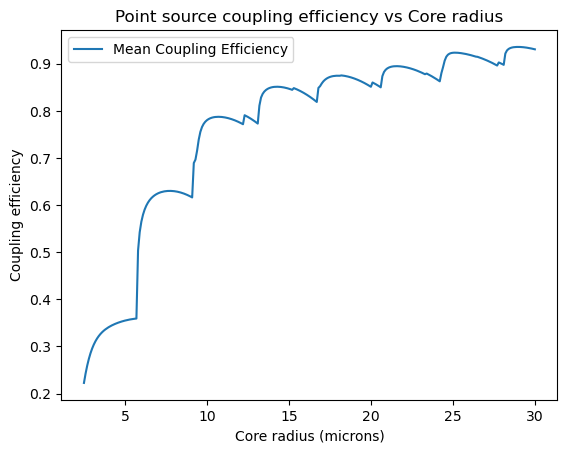

In [148]:
plt.plot(core_radius_range_full * 1e6, eta_mean_psf_cladding, label="Mean Coupling Efficiency")
plt.xlabel('Core radius (microns)')
plt.ylabel('Coupling efficiency')
plt.title('Point source coupling efficiency vs Core radius')
plt.legend()

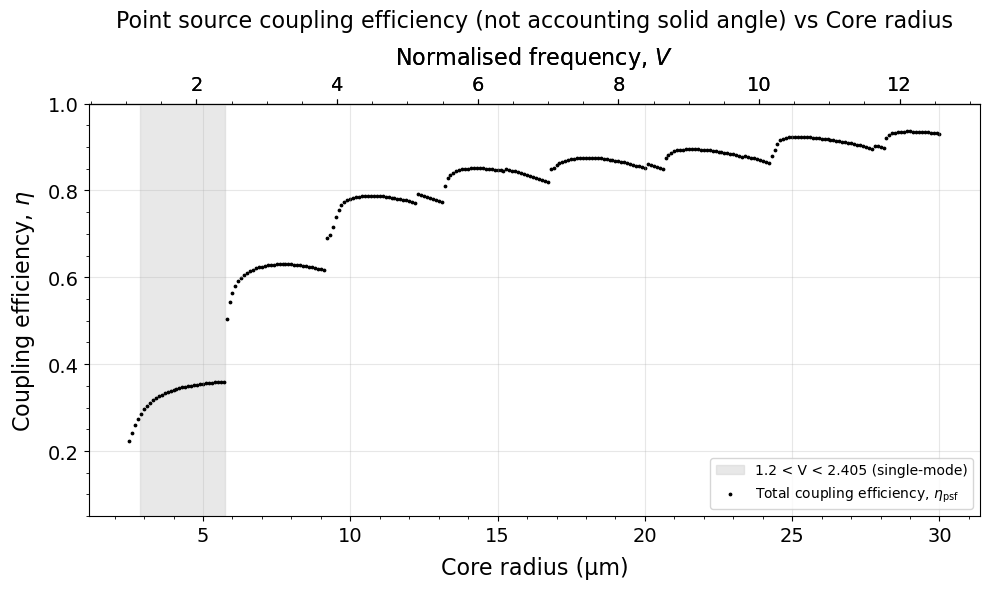

In [149]:
plt.figure(figsize=(10, 6))
ax1 = plt.gca()

# Colour in 1.2 < V < 2.405 region in light grey
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.5,
    label="1.2 < V < 2.405 (single-mode)"
)

ax1.scatter(
    core_radius_range_full * 1e6,
    eta_mean_psf_cladding,
    label=r"Total coupling efficiency, $\eta_{\mathrm{psf}}$",
    color="black",
    s=3
)

ax1.set_xlabel("Core radius (µm)", fontsize=16, labelpad=8)
ax1.set_ylabel(r"Coupling efficiency, $\eta$", fontsize=16, labelpad=8)

ax1.tick_params(axis="x", labelsize=14)
ax1.tick_params(axis="y", labelsize=14)
ax1.minorticks_on()
ax1.grid(True, alpha=0.3)


# -------------------------------------------------
# Top axis: normalised frequency V
# -------------------------------------------------


ax2 = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax2.set_xlabel(
    r"Normalised frequency, $V$",
    fontsize=16,
    labelpad=8
)

ax2.tick_params(axis="x", labelsize=14)

ax2 = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax2.set_xlabel(
    r"Normalised frequency, $V$",
    fontsize=16,
    labelpad=8
)

ax2.tick_params(axis="x", labelsize=14)
ax2.minorticks_on()

plt.ylim(0.05, 1.0)

plt.title("Point source coupling efficiency (not accounting solid angle) vs Core radius", fontsize=16, pad=12)
plt.legend()

plt.tight_layout()
plt.show()


In [167]:
# The background doesn't change, so import data 'results_bg_mmf_core_LIGHT'from the previous calculation.

results_bg_mmf_clad = joblib.load('/Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_bg_mmf_clad_LIGHT.joblib')
eta_bg_clad = np.array([res["eta_background"] for res in results_bg_mmf_core])# [:-1] # from zeroth index to second last index

In [168]:
# SNR plot for core case

I_flat = 1 **2 # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600 # conversion factor from radians to arcseconds

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1) # in arcseconds per meter at the focal plane
plate_scale_demag = plate_scale_coude / Magnification # in arcseconds per meter at the fibre input plane

FOV_array_cladding = np.zeros_like(core_radius_range_full)
snr_array_cladding = np.zeros_like(core_radius_range_full)
signal_array_cladding = np.zeros_like(core_radius_range_full)
background_array_cladding = np.zeros_like(core_radius_range_full)

for i, a in enumerate(core_radius_range_full): 
    # # Calculate Field of View for the fibre
    # # plate scale = FOV / fibre radius, so FOV = plate scale * fibre radius (in arcseconds)
    FOV = plate_scale_demag * 2*a # in arcseconds 

    # r_FOV = np.linspace(0, FOV, 10000) * plate_scale_demag # Convert FOV from arcseconds to meters at the fibre input plane for the core region
    
    # Signal = 2*np.pi * integrate.simpson(I_image * fibre_r, x=fibre_r) # Total signal coupled into the fibre, integrating over the fibre cross-section
    Background_area = np.pi * I_flat * (FOV / 2) **2  # Total noise coupled into the fibre, integrating over the fibre cross-section

    signal_cladding = eta_mean_psf_cladding[i]
    background_cladding = eta_bg_clad[i] * I_flat

    snr_cladding = signal_cladding / np.sqrt(Background_area * background_cladding) # Signal-to-noise ratio, assuming noise is dominated by the background and follows Poisson statistics

    FOV_array_cladding[i] = FOV
    snr_array_cladding[i] = snr_cladding
    signal_array_cladding[i] = signal_cladding
    background_array_cladding[i] = background_cladding

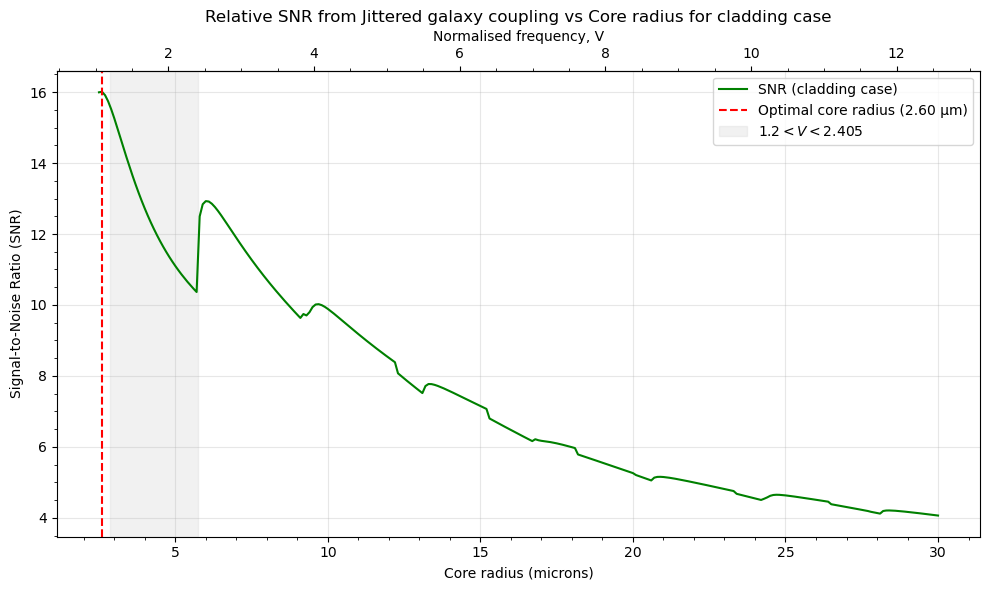

In [169]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(core_radius_range_full*1e6, snr_array_cladding, color='g', label='SNR (cladding case)')
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('SNR vs Core radius for cladding case')

ax1.axvline(core_radius_range_full[np.argmax(snr_array_cladding)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_full[np.argmax(snr_array_cladding)] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('Relative SNR from Jittered galaxy coupling vs Core radius for cladding case')


ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
plt.show()

In [122]:
# Test the results using alternative method, 1D Reyleigh distribution of jittered point source coupling efficiency vs core radius

def rayleigh_pdf(radial_offset, sigma):
    """
    Rayleigh probability density for radial jitter.

    Parameters
    ----------
    radial_offset : array-like
        Radial displacement [m].

    sigma : float
        One-axis RMS jitter at the fibre plane [m].

    Returns
    -------
    pdf : ndarray
        Radial probability density [1/m].
    """ 

    # convert to numpy array
    radial_offset = np.asarray(radial_offset, dtype=float) 

    # Radial probablity density

    pdf = radial_offset / sigma**2 * np.exp(-radial_offset**2 / (2.0 * sigma**2))

    return pdf

In [123]:
# def average_eta_over_rayleigh_jitter(decentre_array, eta_psf_array, sigma_jitter): 
#     """
#     Average coupling efficiency over an isotropic jitter distribution. 

#     Parameters
#     ----------
#     decentre_array : 1D ndarray
#         Radial offsets used to calculate eta_psf_array [m].

#     eta_psf_array : 1D ndarray
#         Coupling efficiency at each radial offset.

#     sigma_jitter : float
#         One-axis RMS jitter at the fibre plane, in units of metres!!!

#     Returns 
#     -------
#     eta_mean: float
#         Mean coupling efficiency, averaged by the Rayleigh jitter distribution. 
    
#     probability_captured: float 
#         Probability that the PSF is contained within the finite offset range of decentre_array 
    
#     probability_density: n array
#         The Rayleigh probability density evaluated at decentre_array, used for weighting the average.

#     """

#     # Calculate the Rayleigh probability density at each radial offset
#     probability_density = rayleigh_pdf(radial_offset=decentre_array, sigma=sigma_jitter)

#     # The numerator of the weighted average is the integral of eta_psf_array * probability_density over decentre_array
#     eta_weighted = np.trapezoid(eta_psf_array * probability_density, x=decentre_array) 

#     # The denominator of the weighted average is the integral of the Rayleigh PDF over decentre_array
#     probability_captured = np.trapezoid(probability_density, x=decentre_array)

#     # eta_mean is the weighted average normlalised by the total probability captured within the finite range of decentre_array
#     eta_mean = eta_weighted / probability_captured

#     return eta_mean, eta_weighted, probability_captured, probability_density

In [124]:
def average_eta_over_rayleigh_jitter(
        decentre_array,
        eta_psf_array,
        sigma_jitter,
        acceptance_radius=None
): 
    """
    Average coupling efficiency over an isotropic jitter distribution. 

    Parameters
    ----------
    decentre_array : 1D ndarray
        Radial offsets used to calculate eta_psf_array [m].

    eta_psf_array : 1D ndarray
        Coupling efficiency at each radial offset.

    sigma_jitter : float
        One-axis RMS jitter at the fibre plane, in units of metres!!!

    acceptance_radius : float or None
        Radial acceptance boundary [m].
        If None, the full calculated radial coupling response is used.

    Returns 
    -------
    eta_mean: float
        Mean coupling efficiency, averaged by the Rayleigh jitter distribution. 
    
    probability_captured: float 
        Probability that the PSF is contained within the finite offset range of decentre_array 
    
    probability_density: n array
        The Rayleigh probability density evaluated at decentre_array, used for weighting the average.

    """

    # Calculate the Rayleigh probability density at each radial offset
    probability_density = rayleigh_pdf(
        radial_offset=decentre_array,
        sigma=sigma_jitter
    )

    # Make a copy of the coupling efficiency array
    eta_psf_array_this = eta_psf_array.copy()

    # Apply the acceptance radius if one is specified
    if acceptance_radius is not None:

        acceptance_mask = (
            decentre_array <= acceptance_radius
        )

        eta_psf_array_this[~acceptance_mask] = 0.0

    # The numerator of the weighted average is the integral of eta_psf_array * probability_density over decentre_array
    eta_weighted = np.trapezoid(
        eta_psf_array_this * probability_density,
        x=decentre_array
    ) 

    # The denominator of the weighted average is the integral of the Rayleigh PDF over decentre_array
    probability_captured = np.trapezoid(
        probability_density,
        x=decentre_array
    )

    # eta_mean is the weighted average normlalised by the total probability captured within the finite range of decentre_array
    eta_mean = eta_weighted / probability_captured

    return eta_mean, eta_weighted, probability_captured, probability_density

In [125]:
# Define function that calculates the mean coupling efficiency for each fibre core radius 
# using the Rayleigh distribution of jittered point source positions

def rayleigh_jittered_point_src_eta_vs_core_radius(
        core_radius_array, 
        eta_fixed_list, 
        decentre_array, 
        sigma_jitter_mas, 
        acceptance_radius="core_radius", 
        n_jobs=1, 
):
    """
    Calculate the mean coupling efficiency for each single-mode fibre core radius using the 
    Rayleigh distribution of jittered point source positions.
    """

    # Convert RMS jitter from milliarcseconds to metres at the fibre plane. 
    sigma_jitter_metres = sigma_jitter_milliarcsec_to_metres(
        sigma_jitter_mas,
        focal_length=f_coude,
        demagnification=Magnification
    )

    # Check that there is one eta(r) array for every core radius. 
    if len(core_radius_array) != len(eta_fixed_list):
        raise ValueError(
            "core_radius_array and eta_fixed_list must have "
            "the same length."
        )

    # Define a function to calculate the mean coupling efficiency for a single core radius.
    def run_one_radius(core_radius, eta_fixed):

        if acceptance_radius == "core_radius":
            acceptance_radius_this = core_radius
        else:
            acceptance_radius_this = acceptance_radius

        eta_mean, eta_weighted, probability_captured, probability_density = average_eta_over_rayleigh_jitter(
            decentre_array=decentre_array,
            eta_psf_array=eta_fixed,
            sigma_jitter=sigma_jitter_metres,
            acceptance_radius=acceptance_radius_this
        )

        return eta_mean

    if n_jobs == 1:

        results = [
            run_one_radius(core_radius, eta_fixed)
            for core_radius, eta_fixed in zip(
                core_radius_array,
                eta_fixed_list
            )
        ]

    else:

        results = Parallel(
            n_jobs=n_jobs,
            verbose=10
        )(
            delayed(run_one_radius)(
                core_radius,
                eta_fixed
            )
            for core_radius, eta_fixed in zip(
                core_radius_array,
                eta_fixed_list
            )
        )

    eta_mean = np.array(results)

    return eta_mean

In [126]:
core_radius_range_smf = core_radius_range_full[core_radius_range_full <= 5.7415e-6]
eta_fixed_list_smf = eta_tot_psf_radial_decentre_list[:len(core_radius_range_smf)]

In [180]:
eta_fixed_list_smf.shape

(33, 500)

In [127]:
eta_mean_psf_rayleigh_core_acceptance = rayleigh_jittered_point_src_eta_vs_core_radius(
    core_radius_array=core_radius_range_smf,
    eta_fixed_list=eta_fixed_list_smf,
    decentre_array=decentre_array_cladding,
    sigma_jitter_mas=20,
    acceptance_radius="core_radius",
    n_jobs=1
)

Text(0, 0.5, 'Coupling efficiency, $\\eta$')

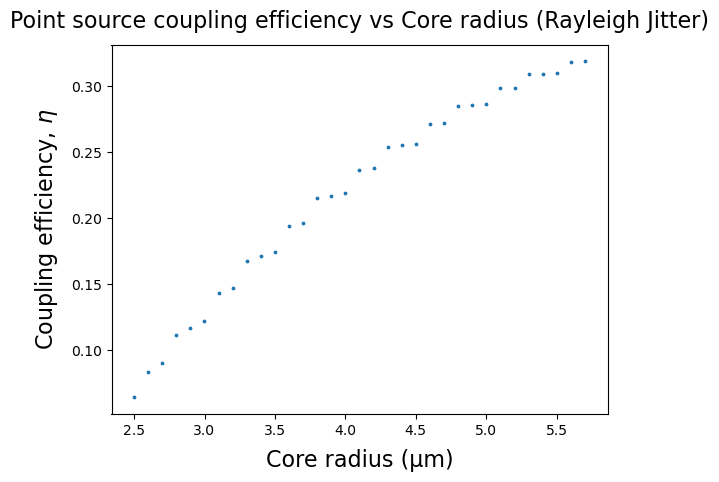

In [128]:
plt.scatter(core_radius_range_smf * 1e6, eta_mean_psf_rayleigh_core_acceptance, s=3, label="Mean Coupling Efficiency (Rayleigh Jitter)")
plt.title("Point source coupling efficiency vs Core radius (Rayleigh Jitter)", fontsize=16, pad=12)
plt.xlabel("Core radius (µm)", fontsize=16, labelpad=8)
plt.ylabel(r"Coupling efficiency, $\eta$", fontsize=16, labelpad=8)
# plt.legend()

In [163]:
# SNR for single-mode radius range using Rayleigh jittered point source coupling efficiency
I_flat = 1 **2 # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600 # conversion factor from radians to arcseconds

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1) # in arcseconds per meter at the focal plane
plate_scale_demag = plate_scale_coude / Magnification # in arcseconds per meter at the fibre input plane

FOV_smf_array = np.zeros_like(core_radius_range_smf)
snr_smf_array = np.zeros_like(core_radius_range_smf)
signal_smf_array = np.zeros_like(core_radius_range_smf)
background_smf_array = np.zeros_like(core_radius_range_smf)

for i, a in enumerate(core_radius_range_smf):
    # Calculate Field of View for the fibre
    # # plate scale = FOV / fibre radius, so FOV = plate scale * fibre radius (in arcseconds)
    FOV_smf = plate_scale_demag * 2*a # in arcseconds
    FOV_smf_array[i] = FOV_smf

    # Background area coupled into the fibre
    Background_area_smf = np.pi * I_flat * (FOV_smf / 2) **2  # Total noise coupled into the fibre, integrating over the fibre cross-section

    signal_smf = eta_mean_psf_rayleigh_core_acceptance[i]
    background_smf = eta_bg_core[i] * I_flat

    snr_smf = signal_smf / np.sqrt(Background_area_smf * background_smf) # Signal-to-noise ratio, assuming noise is dominated by the background and follows Poisson statistics

    FOV_smf_array[i] = FOV_smf
    snr_smf_array[i] = snr_smf
    signal_smf_array[i] = signal_smf
    background_smf_array[i] = background_smf


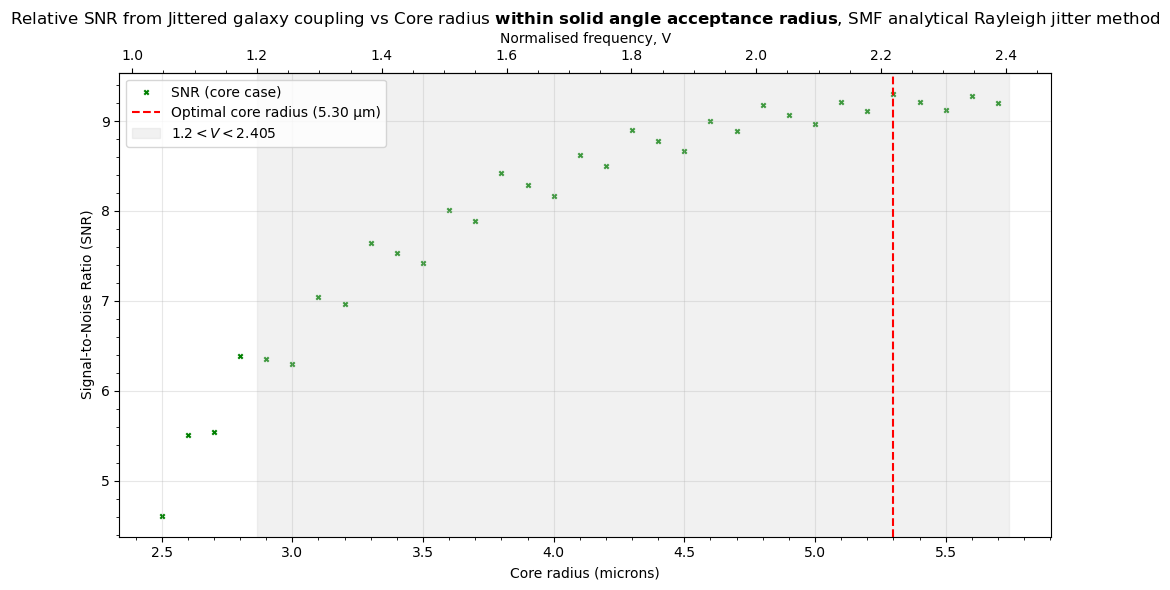

In [181]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.scatter(core_radius_range_smf*1e6, snr_smf_array, color='g', s=10, marker='x', label='SNR (core case)')
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('SNR vs Core radius')

ax1.axvline(core_radius_range_smf[np.argmax(snr_smf_array)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_smf[np.argmax(snr_smf_array)] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title(
    r'Relative SNR from Jittered galaxy coupling vs Core radius '
    r'$\mathbf{within\ solid\ angle\ acceptance\ radius}$, '
    r'SMF analytical Rayleigh jitter method'
)

ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
plt.show()

In [150]:
eta_mean_psf_rayleigh_core_acceptance / eta_mean_psf_core_acceptance[:len(core_radius_range_smf)]

array([0.84163441, 0.96300164, 0.87833743, 0.96590817, 0.91767207,
       0.89143163, 0.96071806, 0.90579524, 0.9844277 , 0.93909644,
       0.91103857, 0.96700459, 0.9450317 , 0.96581236, 0.9484769 ,
       0.92265408, 0.97268349, 0.95742952, 0.99659174, 0.97425127,
       0.9483736 , 0.98675779, 0.95633402, 0.98778244, 0.97509452,
       0.95340205, 0.98368632, 0.9736206 , 0.99573503, 0.98487098,
       0.97627845, 0.99863641, 0.9814476 ])

In [151]:
eta_mean_psf_rayleigh_core_acceptance - eta_mean_psf_core_acceptance[:len(core_radius_range_smf)]

array([-0.01207385, -0.00320845, -0.01251519, -0.00391925, -0.01048813,
       -0.01485215, -0.00584073, -0.01529063, -0.00265158, -0.01109312,
       -0.0169932 , -0.00661095, -0.01141284, -0.00760852, -0.0117878 ,
       -0.01834439, -0.00663481, -0.01057347, -0.00086826, -0.00674483,
       -0.01395738, -0.00363641, -0.01241877, -0.00352606, -0.00730316,
       -0.01401223, -0.00494609, -0.00809718, -0.00132327, -0.00475302,
       -0.00752751, -0.0004348 , -0.00602389])

In [131]:
eta_mean_psf_rayleigh_cladding = rayleigh_jittered_point_src_eta_vs_core_radius(
    core_radius_array=core_radius_range_smf,
    eta_fixed_list=eta_fixed_list_smf,
    decentre_array=decentre_array_cladding,
    sigma_jitter_mas=20,
    acceptance_radius=None,
    n_jobs=1
)

Text(0, 0.5, 'Coupling efficiency, $\\eta$')

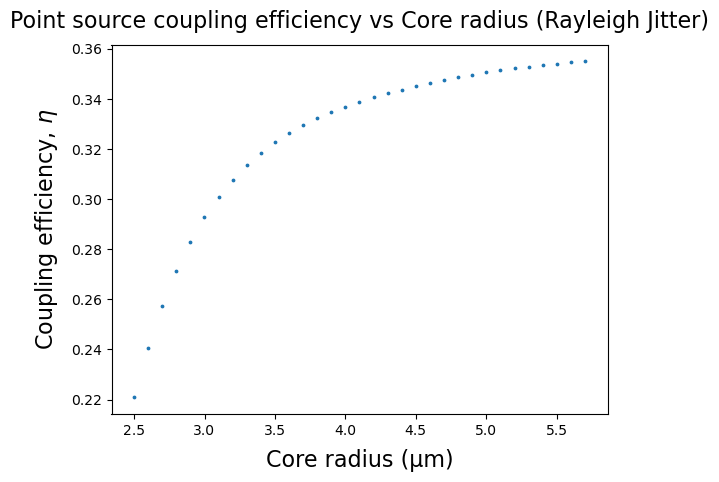

In [132]:
plt.scatter(core_radius_range_smf * 1e6, eta_mean_psf_rayleigh_cladding, s=3, label="Mean Coupling Efficiency (Rayleigh Jitter)")
plt.title("Point source coupling efficiency vs Core radius (Rayleigh Jitter)", fontsize=16, pad=12)
plt.xlabel("Core radius (µm)", fontsize=16, labelpad=8)
plt.ylabel(r"Coupling efficiency, $\eta$", fontsize=16, labelpad=8)

In [177]:
# SNR for single-mode radius range using Rayleigh jittered point source coupling efficiency
I_flat = 1 **2 # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600 # conversion factor from radians to arcseconds

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1) # in arcseconds per meter at the focal plane
plate_scale_demag = plate_scale_coude / Magnification # in arcseconds per meter at the fibre input plane

FOV_smf_array_cladding = np.zeros_like(core_radius_range_smf)
snr_smf_array_cladding = np.zeros_like(core_radius_range_smf)
signal_smf_array_cladding = np.zeros_like(core_radius_range_smf)
background_smf_array_cladding = np.zeros_like(core_radius_range_smf)

for i, a in enumerate(core_radius_range_smf):
    # Calculate Field of View for the fibre
    # # plate scale = FOV / fibre radius, so FOV = plate scale * fibre radius (in arcseconds)
    FOV_smf = plate_scale_demag * 2*a # in arcseconds
    FOV_smf_array[i] = FOV_smf

    # Background area coupled into the fibre
    Background_area_smf = np.pi * I_flat * (FOV_smf / 2) **2  # Total noise coupled into the fibre, integrating over the fibre cross-section

    signal_smf_cladding = eta_mean_psf_rayleigh_cladding[i]
    background_smf_cladding = eta_bg_clad[i] * I_flat

    snr_smf_cladding = signal_smf_cladding / np.sqrt(Background_area_smf * background_smf_cladding) # Signal-to-noise ratio, assuming noise is dominated by the background and follows Poisson statistics

    FOV_smf_array_cladding[i] = FOV_smf
    snr_smf_array_cladding[i] = snr_smf_cladding
    signal_smf_array_cladding[i] = signal_smf_cladding
    background_smf_array_cladding[i] = background_smf_cladding


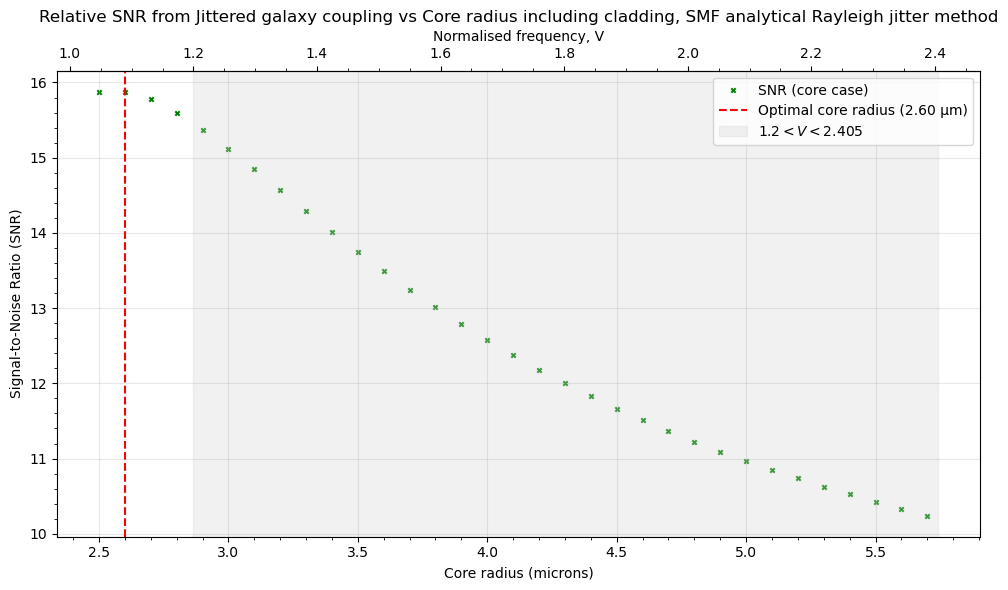

In [179]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.scatter(core_radius_range_smf*1e6, snr_smf_array_cladding, color='g', s=10, marker='x', label='SNR (core case)')
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('SNR vs Core radius')

ax1.axvline(core_radius_range_smf[np.argmax(snr_smf_array_cladding)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_smf[np.argmax(snr_smf_array_cladding)] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('Relative SNR from Jittered galaxy coupling vs Core radius including cladding, SMF analytical Rayleigh jitter method')


ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
plt.show()